# NOAA Weather Time Series Analysis

**Time Series Project — Cohort 18**

**Dataset:** `noaa - 5000.csv` — 5,000 daily weather observations drawn from 1,198 NOAA stations between January and August 2025.

This notebook works through a complete pandas time-series workflow in six steps:

1. Converting raw string dates into `datetime64` with `pd.to_datetime`
2. Building a regular daily calendar with `pd.date_range` and a `DatetimeIndex`
3. Resampling daily data to weekly and monthly frequencies
4. Smoothing daily noise with a 30-day rolling average
5. Extracting calendar attributes and analysing seasonal groupings
6. Visualising raw, rolling, and resampled temperature data

Each step is documented in Markdown — what the operation does and why — followed immediately by the code and its output.

## Step 1 — Converting String Dates to Datetime Objects (`pd.to_datetime`)

Raw date data usually arrives as plain text strings, or split across separate calendar fields. Converting those strings into Pandas `Timestamp` objects (backed by NumPy's `datetime64`) lets Python understand calendar logic, compute time spans, and extract date attributes such as month or day of week. `pd.to_datetime()` flexibly parses many string formats into standard timestamps.

Here the `date` column is text (`2025-07-04`), while `year`, `mo`, and `da` carry the same information as separate integers. We parse both and confirm they agree.

In [1]:
# --- Step 1: parse text dates into Pandas Timestamp objects (datetime64) ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

pd.set_option('display.max_columns', 40)
plt.rcParams['figure.figsize'] = (13, 5)
plt.rcParams['axes.grid'] = True

# Load the real NOAA dataset using a portable, relative path
noaa = pd.read_csv('noaa - 5000.csv')
print('Rows x Columns:', noaa.shape)

# 'date' arrives as a plain string -> convert it to datetime64
noaa['date'] = pd.to_datetime(noaa['date'], format='%Y-%m-%d')

# The separate calendar fields describe the same day, so building a date
# from year/mo/da should reproduce the parsed 'date' column exactly.
from_fields = pd.to_datetime(
    dict(year=noaa['year'], month=noaa['mo'], day=noaa['da'])
)

print('date dtype          :', noaa['date'].dtype)
print('Matches year/mo/da  :', bool((noaa['date'] == from_fields).all()))
print('Stations            :', noaa['stn'].nunique())
print('Date range          :', noaa['date'].min().date(), '->', noaa['date'].max().date())

noaa[['stn', 'date', 'year', 'mo', 'da', 'temp']].head()

Rows x Columns: (5000, 33)
date dtype          : datetime64[us]
Matches year/mo/da  : True
Stations            : 1198
Date range          : 2025-01-01 -> 2025-08-28


,stn,date,year,mo,da,temp
0,10020,2025-07-04,2025,7,4,42.1
1,10020,2025-04-30,2025,4,30,7.6
2,10020,2025-04-19,2025,4,19,2.7
3,10020,2025-04-20,2025,4,20,4.2
4,10020,2025-03-05,2025,3,5,14.4


## Step 2 — Creating Regular Date Sequences (`pd.date_range`) & Datetime Indexing

Setting a `DatetimeIndex` turns a DataFrame into a genuine time-series object. Once indexed by time, Pandas lets you slice intuitively with date strings — `daily.loc['2025-07']` returns every reading from July 2025. `pd.date_range()` generates regular sequences of dates at daily (`'D'`), monthly (`'ME'`/`'MS'`), or hourly (`'h'`) frequencies.

Because the raw file mixes readings from 1,198 stations on overlapping days, we first aggregate each day's observations into a single daily mean, then reindex that series onto a complete calendar.

In [2]:
# --- Step 2a: aggregate by day, then build a regular DatetimeIndex ---

# 1) One daily mean temperature per calendar day (all stations combined)
daily = noaa.groupby('date')['temp'].mean().sort_index()

# 2) A complete, regular daily calendar generated with pd.date_range
full_calendar = pd.date_range(start=daily.index.min(), end=daily.index.max(), freq='D')
print('Days with readings   :', daily.shape[0])
print('Days in calendar     :', len(full_calendar))

# 3) Reindex the aggregated series onto that regular DatetimeIndex
daily = daily.reindex(full_calendar)
missing = daily.index[daily.isna()]
print('Missing calendar days:', int(daily.isna().sum()), '->', [str(d.date()) for d in missing])

# 2025-08-25 has no station readings. Linear interpolation fills that single
# silent day so the rolling statistics in Steps 4 and 6 stay continuous.
daily = daily.interpolate()
print('Remaining NaNs       :', int(daily.isna().sum()))
print('Index type           :', type(daily.index).__name__)

Days with readings   : 239
Days in calendar     : 240
Missing calendar days: 1 -> ['2025-08-25']
Remaining NaNs       : 0
Index type           : DatetimeIndex


In [3]:
# --- Step 2b: date-based slicing is now intuitive ---
print('July 2025 daily means (°F):')
print(daily.loc['2025-07'].round(2))

print('\nFirst week of June 2025 (°F):')
print(daily.loc['2025-06-01':'2025-06-07'].round(2))

# pd.date_range also generates other regular frequencies
print('\nMonth-end sequence (freq = ME):')
print(pd.date_range('2025-01-01', periods=4, freq='ME'))
print('Month-start sequence (freq = MS):')
print(pd.date_range('2025-01-01', periods=4, freq='MS'))

July 2025 daily means (°F):
2025-07-01    64.44
2025-07-02    69.44
2025-07-03    74.35
2025-07-04    62.80
2025-07-05    68.38
2025-07-06    67.87
2025-07-07    75.54
2025-07-08    65.20
2025-07-09    75.24
2025-07-10    74.17
2025-07-11    67.77
2025-07-12    75.62
2025-07-13    70.06
2025-07-14    70.50
2025-07-15    71.80
2025-07-16    73.88
2025-07-17    74.96
2025-07-18    72.98
2025-07-19    73.47
2025-07-20    77.57
2025-07-21    64.83
2025-07-22    64.59
2025-07-23    72.95
2025-07-24    70.41
2025-07-25    66.91
2025-07-26    76.60
2025-07-27    73.29
2025-07-28    75.95
2025-07-29    72.75
2025-07-30    69.82
2025-07-31    48.52
Freq: D, Name: temp, dtype: float64

First week of June 2025 (°F):
2025-06-01    57.23
2025-06-02    66.55
2025-06-03    71.66
2025-06-04    61.25
2025-06-05    72.27
2025-06-06    62.54
2025-06-07    70.90
Freq: D, Name: temp, dtype: float64

Month-end sequence (freq = ME):
DatetimeIndex(['2025-01-31', '2025-02-28', '2025-03-31', '2025-04-30'], dtyp

## Step 3 — Resampling Time-Series Frequencies (`resample`)

Resampling changes the time interval of the data. Downsampling converts higher-frequency data (daily temperatures) into lower-frequency summaries (weekly or monthly means). It behaves like a `groupby` operation built specifically for time intervals.

We aggregate the daily series into **weekly** (`'W'` — weeks ending Sunday) and **monthly** (`'ME'` — calendar month-end, with `'MS'` for month-start anchors) average temperatures.

In [4]:
# --- Step 3: downsample daily -> weekly and monthly ---
weekly  = daily.resample('W').mean()    # weeks ending on Sunday
monthly = daily.resample('ME').mean()   # calendar-month averages (month-end labels)

print('Weekly buckets  :', len(weekly))
print('Monthly buckets :', len(monthly))
print()
print('Weekly average temperature (°F) — first 5 weeks:')
print(weekly.head().round(2))
print()
print('Monthly average temperature (°F):')
print(monthly.round(2))
print()
print('Same data anchored to month-start (freq = MS):')
print(daily.resample('MS').mean().round(2))

Weekly buckets  : 35
Monthly buckets : 8

Weekly average temperature (°F) — first 5 weeks:
2025-01-05    46.89
2025-01-12    45.98
2025-01-19    48.63
2025-01-26    45.99
2025-02-02    45.94
Freq: W-SUN, Name: temp, dtype: float64

Monthly average temperature (°F):
2025-01-31    46.68
2025-02-28    48.82
2025-03-31    55.45
2025-04-30    61.44
2025-05-31    67.00
2025-06-30    66.98
2025-07-31    70.41
2025-08-31    67.52
Freq: ME, Name: temp, dtype: float64

Same data anchored to month-start (freq = MS):
2025-01-01    46.68
2025-02-01    48.82
2025-03-01    55.45
2025-04-01    61.44
2025-05-01    67.00
2025-06-01    66.98
2025-07-01    70.41
2025-08-01    67.52
Freq: MS, Name: temp, dtype: float64


## Step 4 — Smoothing Noise with Rolling Windows (`rolling`)

Raw daily weather is noisy because temperatures jump from one day to the next. A rolling window computes a summary statistic over a sliding frame of consecutive days — here a **30-day moving average** — producing a smooth curve that reveals the broader seasonal trend without discarding the underlying structure.

In [5]:
# --- Step 4: 30-day rolling average to smooth daily spikes ---
rolling_30 = daily.rolling(window=30).mean()

print('The first 29 values are NaN because the window is not yet full:')
print(rolling_30.head(3).round(2))
print()
print('Smoothed 30-day trend — final 5 days (°F):')
print(rolling_30.dropna().tail().round(2))
print()
print('Raw daily std deviation       :', round(daily.std(), 2))
print('30-day smoothed std deviation :', round(rolling_30.std(), 2))
print('-> smoothing damps day-to-day noise while preserving the seasonal shape.')

The first 29 values are NaN because the window is not yet full:
2025-01-01   NaN
2025-01-02   NaN
2025-01-03   NaN
Freq: D, Name: temp, dtype: float64

Smoothed 30-day trend — final 5 days (°F):
2025-08-24    68.83
2025-08-25    68.46
2025-08-26    68.01
2025-08-27    67.48
2025-08-28    66.96
Freq: D, Name: temp, dtype: float64

Raw daily std deviation       : 10.57
30-day smoothed std deviation : 8.28
-> smoothing damps day-to-day noise while preserving the seasonal shape.


## Step 5 — Extracting Calendar Attributes & Analysing Seasonal Groupings

A `DatetimeIndex` exposes built-in attributes such as `.month`, `.dayofweek`, and `.day_name()`. Extracting these lets us regroup the data by calendar period and discover seasonal highs and lows.

In [6]:
# --- Step 5: calendar attributes & seasonal aggregation ---
idx = daily.index

print('Months present        :', sorted(idx.month.unique()))
print('Day-of-week (first 5) :', list(idx.day_name()[:5]))

# Average temperature per calendar month
by_month = daily.groupby(idx.month).mean().round(2)
by_month.index.name = 'month'

# Average temperature per weekday, ordered Monday -> Sunday
dow_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
by_dow = daily.groupby(idx.day_name()).mean().reindex(dow_order).round(2)

print()
print('Average temperature by month (°F):')
print(by_month)
print()
print('Average temperature by day of week (°F):')
print(by_dow)
print()
print('Warmest month     :', int(by_month.idxmax()), '->', by_month.max(), '°F')
print('Coolest month     :', int(by_month.idxmin()), '->', by_month.min(), '°F')
print('Day-of-week spread:', round(by_dow.max() - by_dow.min(), 2), '°F (essentially flat)')

Months present        : [1, 2, 3, 4, 5, 6, 7, 8]
Day-of-week (first 5) : ['Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

Average temperature by month (°F):
month
1    46.68
2    48.82
3    55.45
4    61.44
5    67.00
6    66.98
7    70.41
8    67.52
Name: temp, dtype: float64

Average temperature by day of week (°F):
Monday       61.99
Tuesday      60.02
Wednesday    61.02
Thursday     60.23
Friday       59.58
Saturday     60.83
Sunday       60.30
Name: temp, dtype: float64

Warmest month     : 7 -> 70.41 °F
Coolest month     : 1 -> 46.68 °F
Day-of-week spread: 2.41 °F (essentially flat)


## Step 6 — Visualising Daily, Rolling, and Resampled Temperature Data

Plotting brings the seasonal cycle to life. Overlaying the raw daily readings with the smoothed 30-day rolling curve and the monthly resampled averages compares short-term noise against the overall annual warming and cooling cycle. All three layers are drawn in the same cell before `plt.show()`.

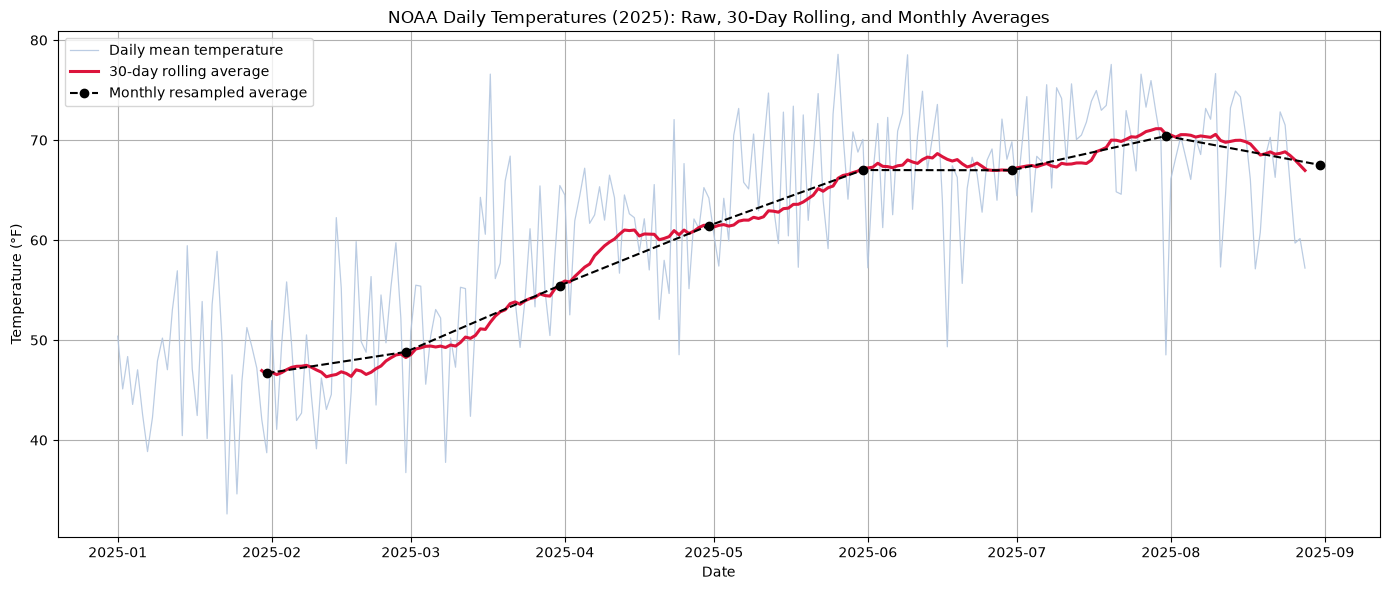

In [7]:
# --- Step 6: raw daily + 30-day rolling + monthly resampled on one chart ---
plt.figure(figsize=(14, 6))

# Layer 1: raw daily means (noisy)
plt.plot(daily.index, daily.values, color='lightsteelblue', linewidth=0.9,
         alpha=0.85, label='Daily mean temperature')

# Layer 2: 30-day rolling average (smoothed trend)
plt.plot(rolling_30.index, rolling_30.values, color='crimson', linewidth=2.2,
         label='30-day rolling average')

# Layer 3: monthly resampled averages (summary points)
plt.plot(monthly.index, monthly.values, color='black', marker='o',
         markersize=6, linewidth=1.5, linestyle='--', label='Monthly resampled average')

plt.title('NOAA Daily Temperatures (2025): Raw, 30-Day Rolling, and Monthly Averages')
plt.xlabel('Date')
plt.ylabel('Temperature (°F)')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

## Conclusion

Across the January–August 2025 window, the NOAA daily mean temperature traces a clear seasonal arc:

- **Warming trend:** monthly averages climb from **46.68 °F in January** to a peak of **70.41 °F in July**, then ease to **67.52 °F in August** (a partial month ending 28 August).
- **Noise vs trend:** the 30-day rolling average smooths out daily spikes — its standard deviation (≈ 8.3 °F) is well below that of the raw daily means (≈ 10.6 °F) — while still tracking the monthly resampled points closely.
- **Seasonality driver:** day-of-week averages are essentially flat (59.58–61.99 °F, a 2.41 °F spread), so the seasonal signal comes from the month, not the weekday.

**Data note:** one calendar day (2025-08-25) has no station readings. The series was reindexed onto a complete daily calendar and that single day was linearly interpolated so the rolling and resampled statistics stay continuous.